In [1]:
# from google.colab import drive
# drive.mount('/content/drive')
import os
os.environ["QT_QPA_PLATFORM"] = "offscreen"
os.listdir("/home/sraoham1/Illicit")

['Baseline-GNNs.ipynb',
 'Baseline-ML.ipynb',
 '.ipynb_checkpoints',
 'shap_decision_plot_node28207.pdf',
 'plot',
 'revise',
 'AblationStudy.ipynb',
 'top10_feature_importance_node23607.pdf',
 'Ellptic_TAGCN.ipynb',
 'data',
 'result']

In [2]:
# import os
# os.chdir('/content/drive/MyDrive/Graph_Neural_Network')

In [3]:
!pip install torch_geometric==2.5.0
!pip install shap
import torch_geometric
from torch_geometric.data import Data, DataLoader
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
import torch.nn.functional as F
import networkx as nx
import seaborn as sns
import os

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [4]:
df_classes = pd.read_csv('./data/elliptic_bitcoin_dataset/elliptic_txs_classes.csv')
df_edges = pd.read_csv('./data/elliptic_bitcoin_dataset/elliptic_txs_edgelist.csv')
df_features = pd.read_csv('./data/elliptic_bitcoin_dataset/elliptic_txs_features.csv', header=None)

In [5]:
# Remove the 'unknown' class and keep only licit/illicit transactions (1/2)
df_classes = df_classes[df_classes['class'] != 'unknown']
df_classes['class'] = df_classes['class'].map({'1': 1, '2': 0})  # 1: illicit, 0: licit

In [6]:
# Merge features with class labels
df_merge = df_features.merge(df_classes, how='inner', right_on="txId", left_on=0)
df_merge = df_merge.drop(['txId'], axis=1)

In [7]:
# ====================== Graph Construction ======================
nodes = df_merge[0].values
map_id = {j: i for i, j in enumerate(nodes)}

edges = df_edges[df_edges.txId1.isin(map_id) & df_edges.txId2.isin(map_id)].copy()
edges.txId1 = edges.txId1.map(map_id)
edges.txId2 = edges.txId2.map(map_id)
edges = edges.astype(int)
edge_index = np.array(edges.values).T
edge_index = torch.tensor(edge_index, dtype=torch.long).contiguous()
weights = torch.tensor([1] * edge_index.shape[1], dtype=torch.float32)

labels = torch.tensor(df_merge['class'].values, dtype=torch.float32)
node_features = torch.tensor(np.array(df_merge.drop([0, 'class', 1], axis=1).values), dtype=torch.float32)

elliptic_dataset = Data(x=node_features, edge_index=edge_index, edge_weights=weights, y=labels)

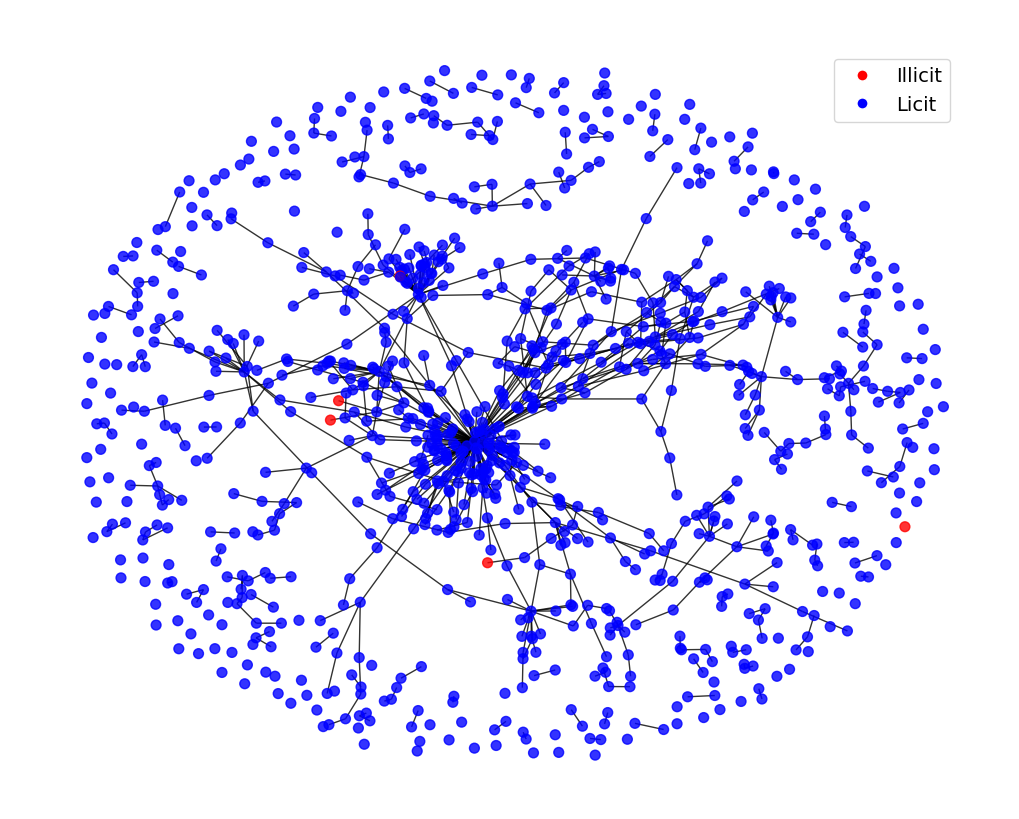

In [8]:
#  Elliptic Dataset 
import networkx as nx
import matplotlib.pyplot as plt
from torch_geometric.utils import to_networkx

sub_nodes = 1000
data_sub = Data(
    x = elliptic_dataset.x[:sub_nodes],
    edge_index = elliptic_dataset.edge_index[:, (elliptic_dataset.edge_index[0] < sub_nodes) & (elliptic_dataset.edge_index[1] < sub_nodes)],
    y = elliptic_dataset.y[:sub_nodes]
)


G_nx = to_networkx(data_sub, to_undirected=True)

# 0=licit，1=illicit
node_labels = data_sub.y.int().tolist()
node_colors = ['red' if label == 1 else 'blue' for label in node_labels]

plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G_nx, seed=42)
nx.draw(G_nx, pos, node_color=node_colors, with_labels=False, node_size=50, alpha=0.8)
# plt.title("Elliptic Dataset Subgraph (First 1000 Nodes)")
red_patch = plt.Line2D([0], [0], marker='o', color='w', label='Illicit',
                       markerfacecolor='red', markersize=8)
blue_patch = plt.Line2D([0], [0], marker='o', color='w', label='Licit',
                        markerfacecolor='blue', markersize=8)
plt.legend(handles=[red_patch, blue_patch],
           loc='upper right',
           bbox_to_anchor=(0.95, 0.95),
           fontsize=14)
plt.axis('off')

plt.savefig('/home/sraoham1/Illicit/plot/result/EllipticSubgraph.png', bbox_inches='tight',pad_inches=0, dpi=300)
plt.show()

Is the full graph connected? No
Number of connected components: 13409
Largest connected component size: 1279


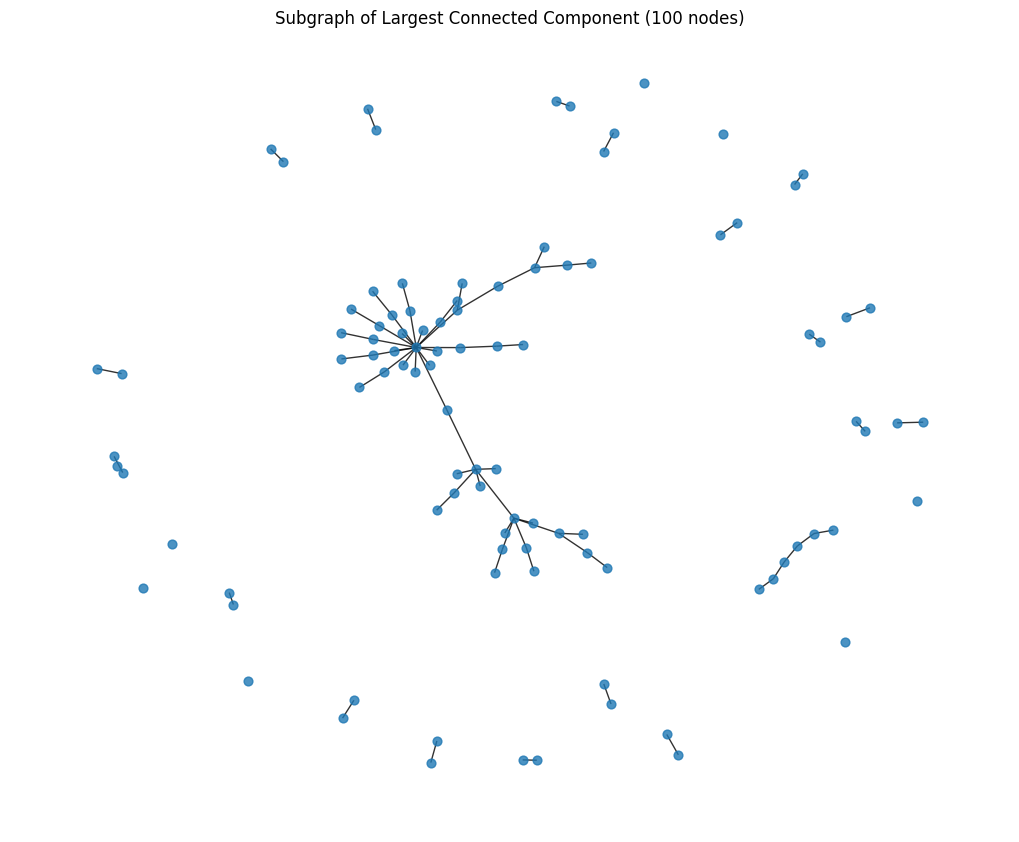

In [9]:
# Graph connectivity check

# Whether the graph is connected

# Number of connected components

# Number of nodes in the largest connected component (giant component)

# Convert the graph to an undirected graph to perform the connectivity analysis

G_nx_all = to_networkx(elliptic_dataset, to_undirected=True)


is_connected = nx.is_connected(G_nx_all)
print(f"Is the full graph connected? {'Yes' if is_connected else 'No'}")


connected_components = list(nx.connected_components(G_nx_all))
print(f"Number of connected components: {len(connected_components)}")

largest_cc = max(connected_components, key=len)
print(f"Largest connected component size: {len(largest_cc)}")


G_lcc = G_nx_all.subgraph(list(largest_cc)[:100])
plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G_lcc, seed=123)
nx.draw(G_lcc, pos, node_size=40, alpha=0.8)
plt.title("Subgraph of Largest Connected Component (100 nodes)")
plt.show()

In [10]:

seed = 0
learning_rate = 0.005
weight_decay = 1e-5
input_dim = 165
output_dim = 1
hidden_size = 150
num_epochs = 400
checkpoints_dir = './result/models/elliptic_tgnn'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [11]:

all_idx = np.arange(len(labels))
y_all = labels[all_idx]

train_idx, temp_idx = train_test_split(all_idx, test_size=0.3, random_state=seed, stratify=y_all)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, random_state=seed, stratify=labels[temp_idx])

In [12]:
def get_split_stats(split_idx, edge_index, labels):
    node_mask = np.zeros(len(labels), dtype=bool)
    node_mask[split_idx] = True
    split_labels = labels[split_idx]

    licit_count = int((split_labels == 0).sum())
    illicit_count = int((split_labels == 1).sum())
    total_nodes = len(split_idx)


    mask_edges = node_mask[edge_index[0]] & node_mask[edge_index[1]]
    edge_count = int(mask_edges.sum())

    illicit_ratio = illicit_count / total_nodes * 100

    return licit_count, illicit_count, total_nodes, edge_count, illicit_ratio


train_stats = get_split_stats(train_idx, edge_index, labels)
val_stats = get_split_stats(val_idx, edge_index, labels)
test_stats = get_split_stats(test_idx, edge_index, labels)


total_stats = get_split_stats(np.arange(len(labels)), edge_index, labels)


from tabulate import tabulate

table = [
    ["Training", *train_stats],
    ["Validation", *val_stats],
    ["Test", *test_stats],
    ["Total", *total_stats]
]

headers = ["Dataset Split", "Licit Nodes", "Illicit Nodes", "Total Nodes", "Total Edges", "Illicit Ratio (%)"]
print(tabulate(table, headers=headers, tablefmt="github", floatfmt=".1f"))

| Dataset Split   |   Licit Nodes |   Illicit Nodes |   Total Nodes |   Total Edges |   Illicit Ratio (%) |
|-----------------|---------------|-----------------|---------------|---------------|---------------------|
| Training        |         29413 |            3181 |         32594 |         18336 |                 9.8 |
| Validation      |          6303 |             682 |          6985 |           817 |                 9.8 |
| Test            |          6303 |             682 |          6985 |           731 |                 9.8 |
| Total           |         42019 |            4545 |         46564 |         36624 |                 9.8 |


In [13]:
elliptic_dataset.train_idx = torch.tensor(train_idx, dtype=torch.long)
elliptic_dataset.val_idx = torch.tensor(val_idx, dtype=torch.long)
elliptic_dataset.test_idx = torch.tensor(test_idx, dtype=torch.long)

In [14]:
class TGNN(torch.nn.Module):
    def __init__(self, dim_in, dim_h, dim_out, K=3):
        super().__init__()
        self.norm1 = torch.nn.BatchNorm1d(dim_in)
        self.gat1 = torch_geometric.nn.conv.TAGConv(dim_in, dim_h, K)
        self.norm2 = torch.nn.BatchNorm1d(dim_h)
        self.gat2 = torch_geometric.nn.conv.TAGConv(dim_h, dim_out, K)

    def forward(self, x, edge_index):
        h = self.norm1(x)
        h = self.gat1(h, edge_index)
        h = self.norm2(h)
        h = F.leaky_relu(h)
        out = self.gat2(h, edge_index)
        return out

def accuracy(y_pred, y_test, prediction_threshold=0.5):
    y_pred_label = (torch.sigmoid(y_pred) > prediction_threshold).float()
    correct_results_sum = (y_pred_label == y_test).sum().float()
    acc = correct_results_sum / y_test.shape[0]
    return acc

def train(model, data, criterion, optimizer, *args):
    num_epochs = args[0]
    checkpoint_dir = args[1]
    model_filename = args[2]

    if not os.path.exists(checkpoint_dir):
        os.makedirs(checkpoint_dir)

    best_loss = float('inf')
    model.train()

    for epoch in range(num_epochs):
        optimizer.zero_grad()
        pred = model(data.x, data.edge_index)
        loss = criterion(pred[data.train_idx], data.y[data.train_idx].unsqueeze(1))
        acc = accuracy(pred[data.train_idx], data.y[data.train_idx].unsqueeze(1))

        loss.backward()
        optimizer.step()

        val_loss = criterion(pred[data.val_idx], data.y[data.val_idx].unsqueeze(1))
        val_acc = accuracy(pred[data.val_idx], data.y[data.val_idx].unsqueeze(1))

        if epoch % 10 == 0:
            print(f'Epoch {epoch:>3} | Train Loss: {loss:.3f} | Train Acc: '
                  f'{acc*100:>6.2f}% | Val Loss: {val_loss:.4f} | '
                  f'Val Acc: {val_acc*100:.2f}%')
            if val_loss < best_loss:
                best_loss = val_loss
                print('Saving best model state')
                checkpoint = {'state_dict': model.state_dict()}
                torch.save(checkpoint, os.path.join(checkpoint_dir, model_filename))

    return model

def test(model, data):
    model.eval()
    preds = model(data.x, data.edge_index)
    preds = ((torch.sigmoid(preds) > 0.5).float() * 1).squeeze(1)
    return preds

In [15]:
torch.manual_seed(seed)

model = TGNN(input_dim, hidden_size, output_dim, K=3).to(device)
data_train = elliptic_dataset.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
criterion = torch.nn.BCEWithLogitsLoss()

train(model, data_train, criterion, optimizer, num_epochs, checkpoints_dir, 'tgnn_best_model.pth.tar')

Epoch   0 | Train Loss: 0.688 | Train Acc:  47.30% | Val Loss: 0.6869 | Val Acc: 47.97%
Saving best model state
Epoch  10 | Train Loss: 0.192 | Train Acc:  90.86% | Val Loss: 0.1921 | Val Acc: 90.82%
Saving best model state
Epoch  20 | Train Loss: 0.157 | Train Acc:  94.01% | Val Loss: 0.1587 | Val Acc: 94.09%
Saving best model state
Epoch  30 | Train Loss: 0.140 | Train Acc:  96.22% | Val Loss: 0.1432 | Val Acc: 96.15%
Saving best model state
Epoch  40 | Train Loss: 0.124 | Train Acc:  96.68% | Val Loss: 0.1287 | Val Acc: 96.45%
Saving best model state
Epoch  50 | Train Loss: 0.110 | Train Acc:  96.90% | Val Loss: 0.1159 | Val Acc: 96.55%
Saving best model state
Epoch  60 | Train Loss: 0.099 | Train Acc:  97.10% | Val Loss: 0.1072 | Val Acc: 96.79%
Saving best model state
Epoch  70 | Train Loss: 0.091 | Train Acc:  97.29% | Val Loss: 0.1019 | Val Acc: 96.86%
Saving best model state
Epoch  80 | Train Loss: 0.085 | Train Acc:  97.43% | Val Loss: 0.0979 | Val Acc: 96.96%
Saving best mode

TGNN(
  (norm1): BatchNorm1d(165, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (gat1): TAGConv(165, 150, K=3)
  (norm2): BatchNorm1d(150, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (gat2): TAGConv(150, 1, K=3)
)

In [16]:
model.load_state_dict(torch.load(os.path.join(checkpoints_dir, 'tgnn_best_model.pth.tar'))['state_dict'])
#model.load_state_dict(torch.load(os.path.join('/home/sraoham1/Illicit/plot/result/models/elliptic_tgnn_ablation/tgnn_best_model_K3.pth.tar'))['state_dict'])
y_test_preds = test(model, data_train)

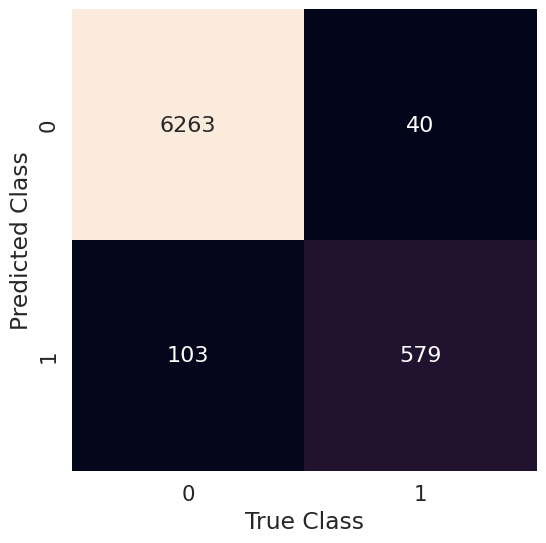

              precision    recall  f1-score   support

       licit       0.98      0.99      0.99      6303
     illicit       0.94      0.85      0.89       682

    accuracy                           0.98      6985
   macro avg       0.96      0.92      0.94      6985
weighted avg       0.98      0.98      0.98      6985



In [17]:
conf_mat = confusion_matrix(data_train.y[data_train.test_idx].cpu().numpy(),
                            y_test_preds[data_train.test_idx].cpu())

plt.figure(figsize=(6,6))
sns.set(font_scale=1.4)
sns.heatmap(conf_mat, annot=True, fmt=".0f", annot_kws={"size": 16}, cbar=False)
plt.xlabel('True Class'); plt.ylabel('Predicted Class');
# plt.title('Confusion Matrix')
plt.savefig("./result/ConfusionMatrix.png", dpi=300, bbox_inches='tight')
plt.show()

print(classification_report(data_train.y[data_train.test_idx].cpu().numpy(),
                            y_test_preds[data_train.test_idx].cpu(),
                            target_names=['licit', 'illicit']))

In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef

model.eval()

with torch.no_grad():
    output = model(data_train.x, data_train.edge_index)
    prob = torch.sigmoid(output[data_train.test_idx]).squeeze().cpu().numpy()
    y_pred = (prob > 0.5).astype(int)
    y_true = data_train.y[data_train.test_idx].cpu().numpy().astype(int)

# average='binary'
acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
mcc = matthews_corrcoef(y_true, y_pred)

print(f"\nTest Metrics:")
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"MCC:       {mcc:.4f}")


Test Metrics:
Accuracy:  0.9795
Precision: 0.9354
Recall:    0.8490
F1-score:  0.8901
MCC:       0.8801


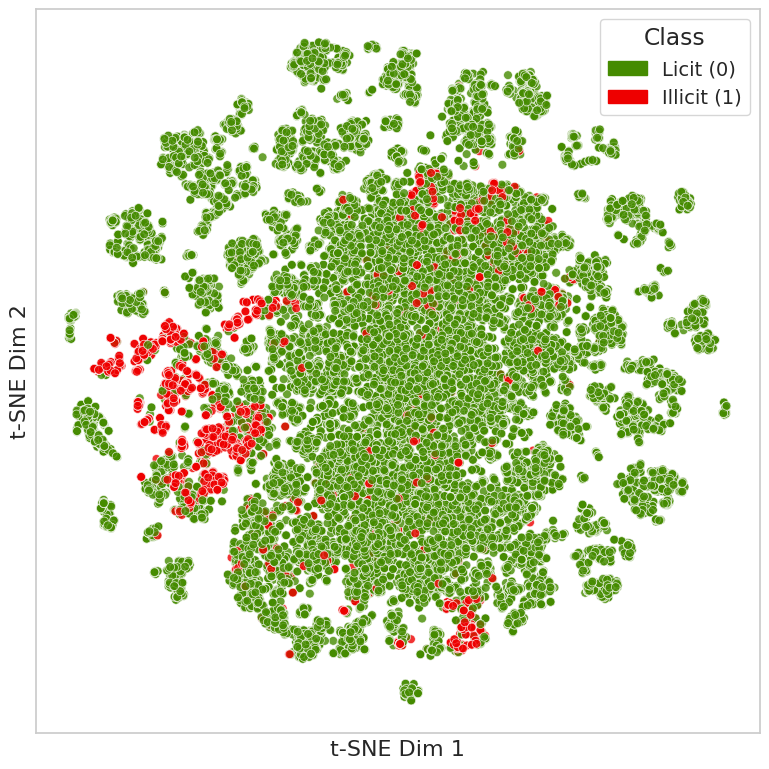

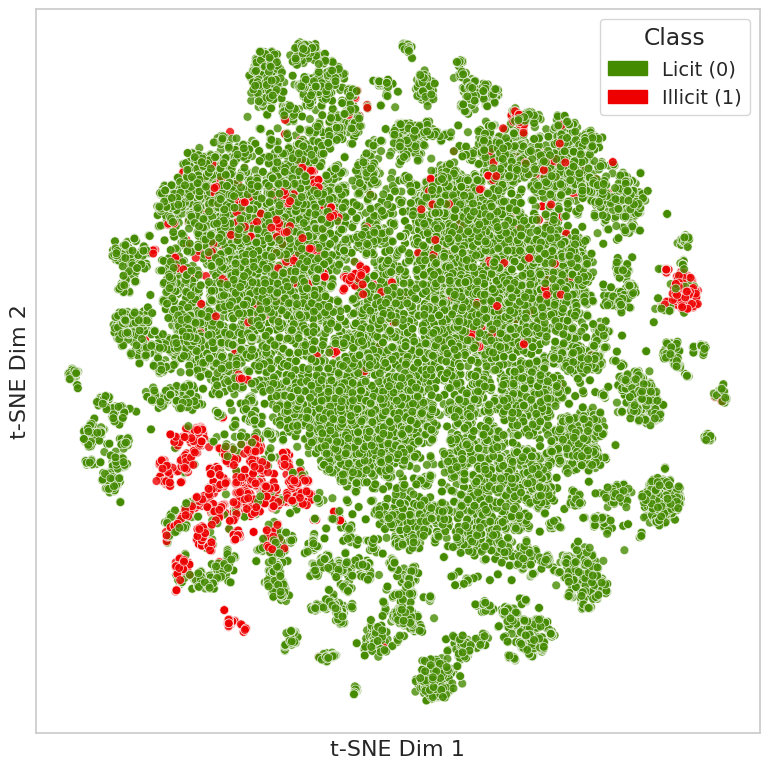

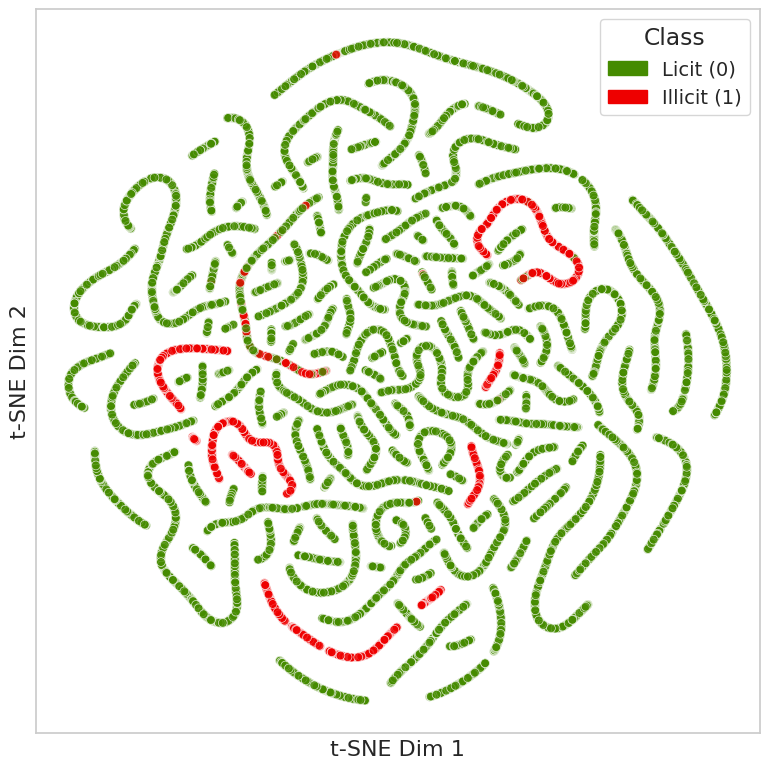

In [19]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

def tsne_visualize(features, labels, title, filename, perplexity=30):
    """
    Use t-SNE for 2D visualization and plot classification scatter plot
    """
    # Standardize features (helps t-SNE converge)
    features = StandardScaler().fit_transform(features)

    # t-SNE dimensionality reduction
    z = TSNE(n_components=2, perplexity=perplexity, init='random', random_state=42).fit_transform(features)

    # Visualization settings
    plt.figure(figsize=(8, 8))
    sns.set_style("whitegrid")

    palette = ["#458B00", "#EE0000"]
    legend_labels = ["Licit (0)", "Illicit (1)"]
    handles = [Patch(color=palette[i], label=legend_labels[i]) for i in range(2)]

    scatter = sns.scatterplot(x=z[:, 0], y=z[:, 1], hue=labels, palette=palette, s=40, alpha=0.8)
    plt.title(title, fontsize=16)
    plt.xlabel("t-SNE Dim 1", fontsize=16)
    plt.ylabel("t-SNE Dim 2", fontsize=16)
    plt.xticks([])
    plt.yticks([])
    plt.legend(handles=handles, title="Class", loc='best', fontsize=14)
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()


# -------- Load the model and compute intermediate feature representations --------
model.eval()

# Original node features (training set)
x_train = data_train.x[data_train.train_idx].cpu().numpy()
y_train = data_train.y[data_train.train_idx].cpu().numpy()

# First-layer representations of the model
with torch.no_grad():
    h1 = model.norm1(data_train.x)
    h1 = model.gat1(h1, data_train.edge_index)
    h1_train = h1[data_train.train_idx].cpu().numpy()

# Second-layer representations of the model
with torch.no_grad():
    h1 = model.norm1(data_train.x)
    h1 = model.gat1(h1, data_train.edge_index)
    h1 = model.norm2(h1)
    h1 = F.leaky_relu(h1)
    h2 = model.gat2(h1, data_train.edge_index)
    h2_train = h2[data_train.train_idx].cpu().numpy()


# -------- Call the function for visualization --------
tsne_visualize(x_train, y_train, title="", filename="./result/train_tsne_raw_features.png")
tsne_visualize(h1_train, y_train, title="", filename="./result/train_tsne_tgnn_first_layer_features.png")
tsne_visualize(h2_train, y_train, title="", filename="./result/train_tsne_tgnn_second_layer_features.png")

In [20]:
from collections import Counter

# 1. Count the degree of all nodes (number of connected edges)
all_degrees = Counter(edge_index[0].tolist() + edge_index[1].tolist())

# 2. Get the indices of nodes in the training set
train_nodes = elliptic_dataset.train_idx.tolist()

# 3. Get nodes in the training set with class == 1 (illicit transactions)
train_class_1_nodes = [node for node in train_nodes if labels[node] == 1]

# 4. Among these nodes, select those with degree > 4
train_high_degree_class_1_nodes = [node for node in train_class_1_nodes if all_degrees[node] > 4]

print(f"Number of nodes in the training set with class=1 and degree>4: {len(train_high_degree_class_1_nodes)}")
print(f"Example node indices: {train_high_degree_class_1_nodes[:10]}")

Number of nodes in the training set with class=1 and degree>4: 22
Example node indices: [23607, 29390, 17494, 31401, 44965, 18000, 35560, 32943, 29407, 31473]


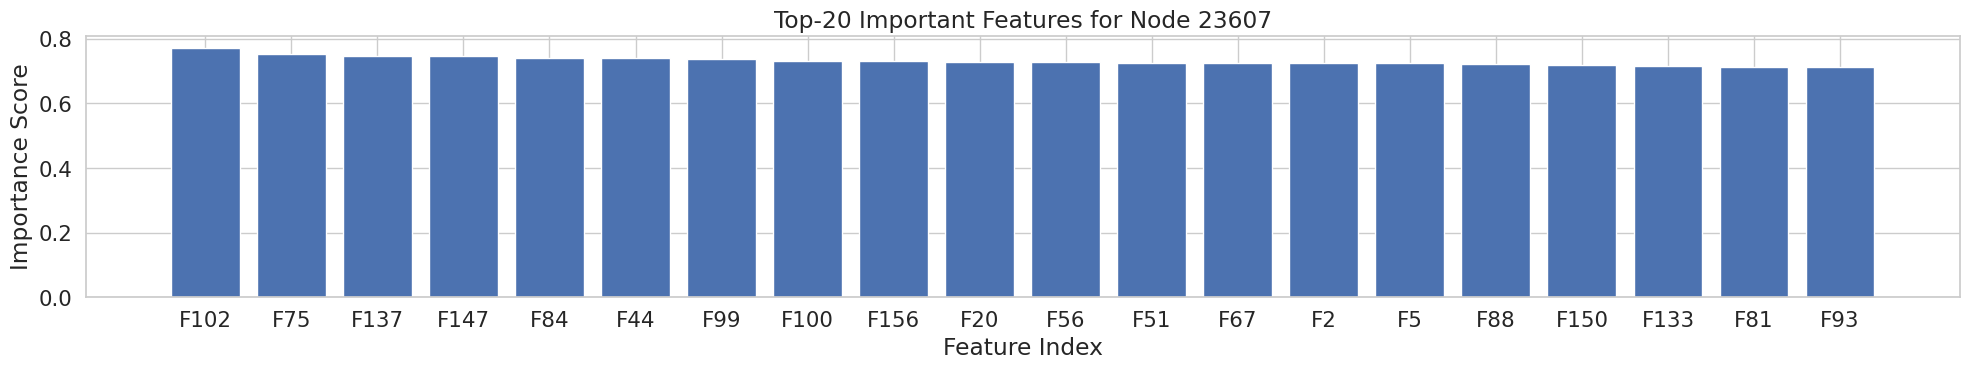

In [21]:
# ---------------------------
# 4. Use GNNExplainer to obtain structural and feature importance
# ---------------------------
from torch_geometric.explain import Explainer, GNNExplainer
from torch_geometric.explain.config import ModelConfig, ExplainerConfig

model.eval()

# Build the Explainer
explainer = Explainer(
    model=model,
    algorithm=GNNExplainer(epochs=100),
    explanation_type='model',
    model_config=ModelConfig(
        mode='multiclass_classification',
        task_level='node',
        return_type='log_probs'
    ),
    node_mask_type='attributes',
    edge_mask_type='object'
)

# Select a node from the test set to explain
node_idx = 23607
explanation = explainer(x=data_train.x, edge_index=data_train.edge_index, index=node_idx)

import matplotlib.pyplot as plt
import numpy as np

feature_importance = explanation.node_mask[node_idx].detach().cpu().numpy()

# Get the indices and weights of the Top-20 features
topk = 20
topk_idx = np.argsort(feature_importance)[-topk:][::-1]  # Sort from largest to smallest
topk_values = feature_importance[topk_idx]

# Visualization
plt.figure(figsize=(20, 4))
plt.bar(range(topk), topk_values, tick_label=[f"F{idx}" for idx in topk_idx])
plt.xlabel("Feature Index")
plt.ylabel("Importance Score")
plt.title(f"Top-{topk} Important Features for Node {node_idx}")
plt.tight_layout()
plt.savefig('top10_feature_importance_node23607.pdf')
plt.show()

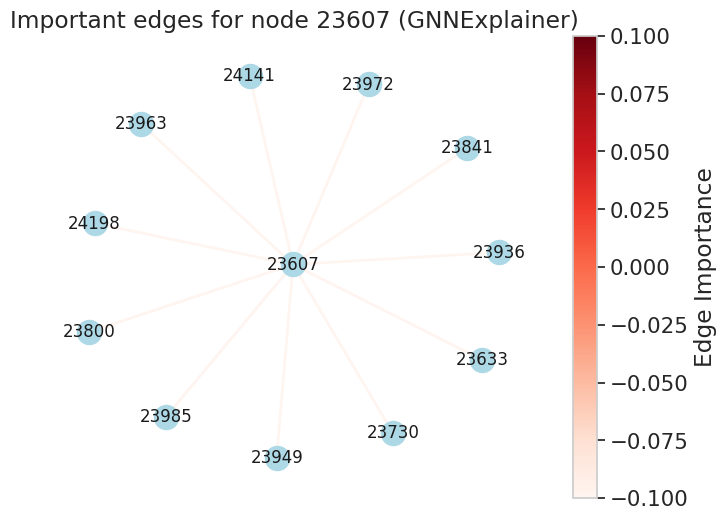

In [22]:
# Structural Importance Analysis: identify which edges (neighbor relationships)
# most influence the classification result of a node
"""
Core idea: Evaluate the importance of each edge (or connection between nodes)
in the graph for the model's prediction.

Output format: Usually a weight vector with the same length as the number of edges
(edge_mask). Each value represents the contribution or importance of the
corresponding edge to the prediction. Larger values indicate more critical edges.

Purpose: Quantitatively identify which connections/neighbors have the greatest
influence on the model’s prediction.

Example: For node 10's prediction, edge (10,15) has a weight of 0.8 while
edge (10,20) has a weight of 0.1, meaning edge (10,15) has more influence
on the result than edge (10,20).
"""

from torch_geometric.utils import k_hop_subgraph, to_networkx
import matplotlib.pyplot as plt
import networkx as nx
import matplotlib as mpl

node_idx = 23607  # Node to be explained
num_hops = 3      # Number of neighborhood hops

# Extract subgraph nodes/edges indices
subset, edge_index_sub, mapping, hard_edge_mask = k_hop_subgraph(
    node_idx, num_hops=num_hops, edge_index=data_train.edge_index, relabel_nodes=True)

# Extract edge mask for the subgraph from the full graph
# (make sure to match edges to their corresponding mask values)
full_edge_mask = explanation.edge_mask.detach().cpu().numpy()

# Build NetworkX graph
G = to_networkx(data_train, to_undirected=True)

# Get the subgraph
G_sub = G.subgraph(subset.tolist())

# Generate mask values for each edge in the subgraph (lookup from original edge_index)
edge_mask_dict = {}
edge_tuples = data_train.edge_index.t().tolist()  # all edges (source, target)

for i, (src, dst) in enumerate(edge_tuples):
    if src in subset and dst in subset:
        edge_mask_dict[(src, dst)] = full_edge_mask[i]
        edge_mask_dict[(dst, src)] = full_edge_mask[i]  # because the graph is undirected

# Mask values for each edge in the subgraph
edge_colors = []
for src, dst in G_sub.edges():
    val = edge_mask_dict.get((src, dst), 0.0)
    edge_colors.append(val)

# Plot the graph
plt.figure(figsize=(8, 6))
ax = plt.gca()
nx.draw_networkx(
    G_sub,
    with_labels=True,
    node_color='lightblue',
    edge_color=edge_colors,
    edge_cmap=plt.cm.Reds,
    width=2
)

# Create a ScalarMappable with the data range
norm = mpl.colors.Normalize(vmin=min(edge_colors), vmax=max(edge_colors))
sm = mpl.cm.ScalarMappable(cmap=plt.cm.Reds, norm=norm)
sm.set_array([])  # set_array must be called (argument can be empty)

# Add a colorbar bound to the current axis
plt.colorbar(sm, ax=ax, label='Edge Importance')

plt.title(f"Important edges for node {node_idx} (GNNExplainer)")
plt.axis('off')
plt.show()

/etc/python/sitecustomize.py:117: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  mod = _original_import(name, globals, locals, fromlist, level)
PermutationExplainer explainer: 2it [00:58, 58.71s/it]               


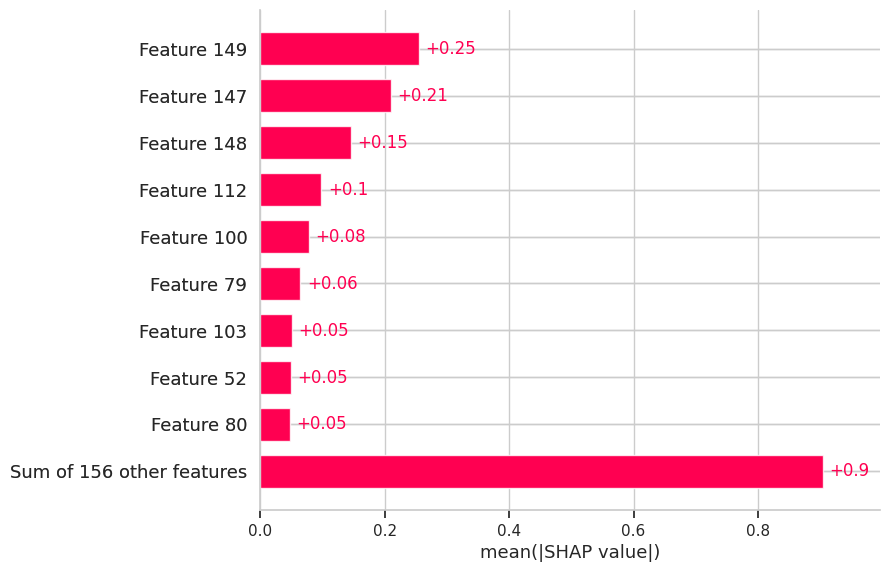

/tmp/ipykernel_72850/4098189258.py:41: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values.values, features=node_feat_batch, feature_names=feature_names, plot_type="bar", show=True)


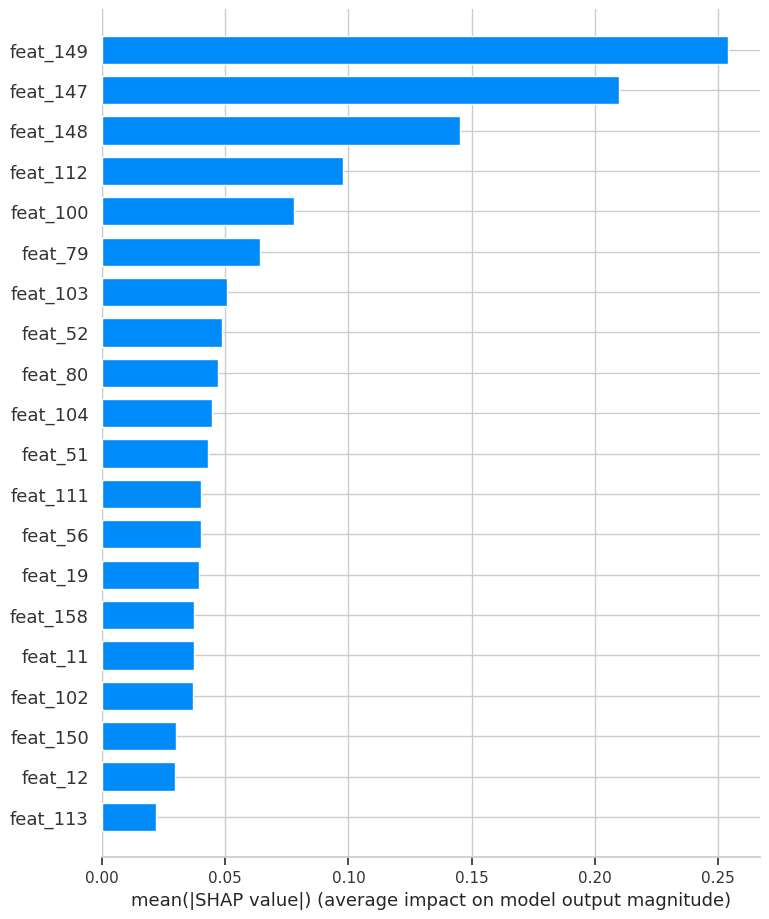

In [23]:
import shap
import numpy as np
import torch.nn.functional as F

# ---------------------------
# 5. Use SHAP to analyze node feature importance
# ---------------------------

def model_predict(x_numpy_batch):
    model.eval()
    x_clone = data_train.x.clone().to(device)
    outputs = []
    with torch.no_grad():
        for i in range(x_numpy_batch.shape[0]):
            # Replace the node features for the target node in the batch
            x_clone[node_idx] = torch.tensor(x_numpy_batch[i], dtype=torch.float32, device=device)
            out = model(x_clone, data_train.edge_index)
            prob = torch.sigmoid(out)[node_idx]
            outputs.append(prob.cpu().numpy())
    return np.array(outputs)

# Select multiple nodes
num_samples = 1
all_indices = np.arange(data_train.x.shape[0])
sample_indices = np.random.choice(all_indices, size=num_samples, replace=False)
node_feat_batch = data_train.x[sample_indices].cpu().numpy()

# Initialize SHAP explainer
explainer = shap.Explainer(model_predict, masker=shap.maskers.Independent(data_train.x.cpu().numpy()))

# Compute SHAP values
shap_values = explainer(node_feat_batch)

# Plot SHAP bar plot
shap.plots.bar(shap_values)

# Prepare feature names
feature_names = [f'feat_{i}' for i in range(node_feat_batch.shape[1])]

# SHAP summary plot (bar)
shap.summary_plot(shap_values.values, features=node_feat_batch, feature_names=feature_names, plot_type="bar", show=True)

# Save figure
plt.savefig("./result/shap_summary_plot.png", dpi=300, bbox_inches='tight')
plt.close()

/tmp/ipykernel_72850/1445209002.py:2: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values.values, features=node_feat_batch, feature_names=feature_names, show=True)


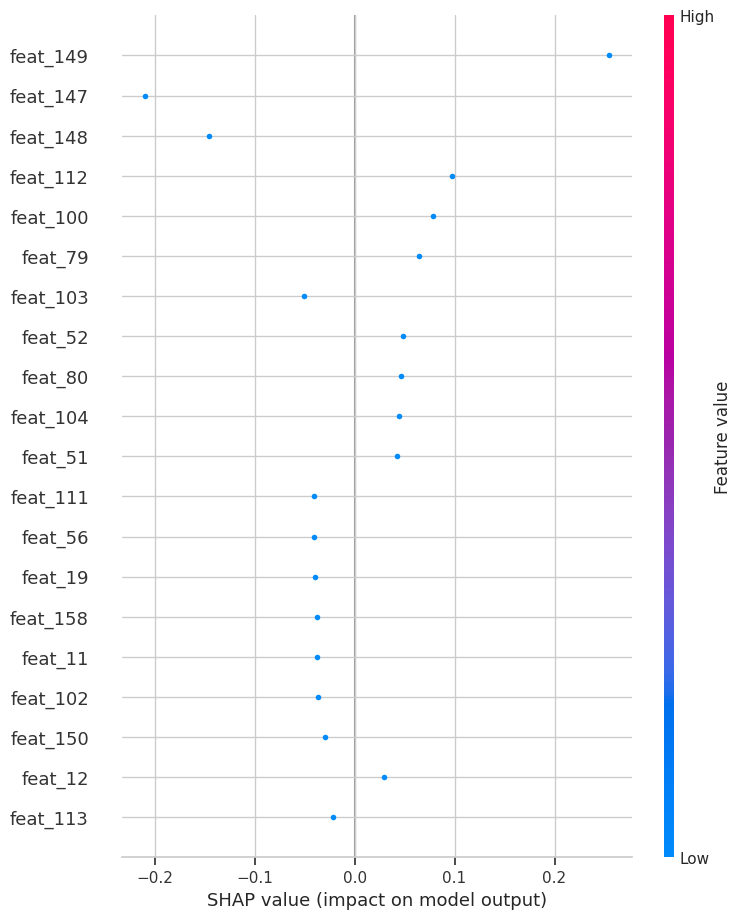

In [24]:
# SHAP summary plot (bar chart)
shap.summary_plot(shap_values.values, features=node_feat_batch, feature_names=feature_names, show=True)
plt.savefig("./result/shap_summary_plot.png", dpi=300, bbox_inches='tight')
plt.close()

# Uncomment the following lines to generate a SHAP dependence plot for a specific feature
# shap.dependence_plot("Time", shap_values.values, features=node_feat_batch, feature_names=feature_names, show=True)
# plt.savefig("./result/shap_dependence_plot.png", dpi=300, bbox_inches='tight')
# plt.close()

PermutationExplainer explainer: 2it [00:48, 48.27s/it]               


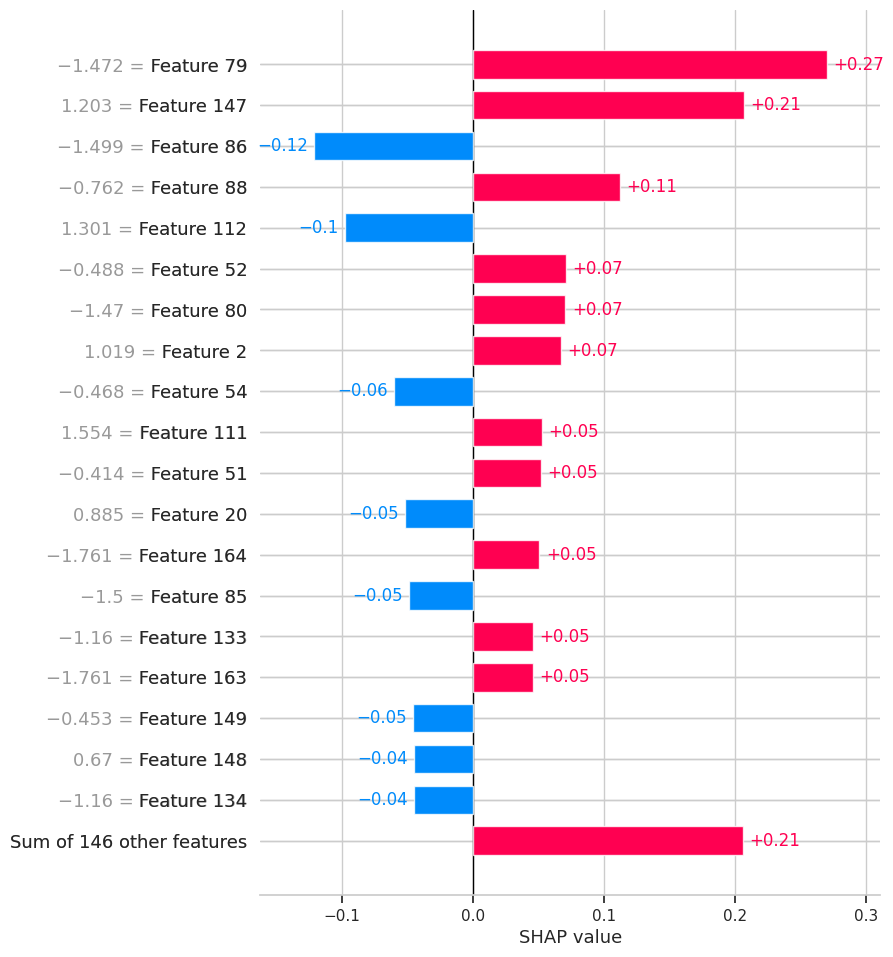

In [25]:
import shap

# Feature importance explanation for a single node (bar plot)
node_idx = 28207  # Fixed node ID

def model_predict(x_numpy_batch):
    model.eval()
    x_clone = data_train.x.clone().to(device)
    outputs = []
    with torch.no_grad():
        for i in range(x_numpy_batch.shape[0]):
            # Replace the features of the target node in the batch
            x_clone[node_idx] = torch.tensor(x_numpy_batch[i], dtype=torch.float32, device=device)
            out = model(x_clone, data_train.edge_index)
            prob = torch.sigmoid(out)[node_idx]
            outputs.append(prob.cpu().numpy())
    return np.array(outputs)

# Prepare feature vector for the single node
node_feat = data_train.x[node_idx].cpu().numpy().reshape(1, -1)

# Initialize SHAP explainer
explainer = shap.Explainer(model_predict, masker=shap.maskers.Independent(data_train.x.cpu().numpy()))

# Compute SHAP values for the node
shap_values = explainer(node_feat)

# Plot SHAP bar chart for the top 20 features
shap.plots.bar(shap_values[0], max_display=20)
plt.tight_layout()
plt.savefig("./result/shap_node28207.png", dpi=300)
plt.close()

In [26]:
# The Force Plot is a classic SHAP visualization.
# It shows, like a “tug-of-war” diagram, how each feature pushes the model
# from the expected value (baseline) to the final prediction.
# Useful for illustrating the detailed explanation of a specific "illicit transaction" in a paper.

shap.initjs()
shap.plots.force(shap_values[0])

# Optionally, save the Force Plot as an interactive HTML file
# shap.save_html("./result/force_plot_node28207.html", shap.plots.force(shap_values[0]))

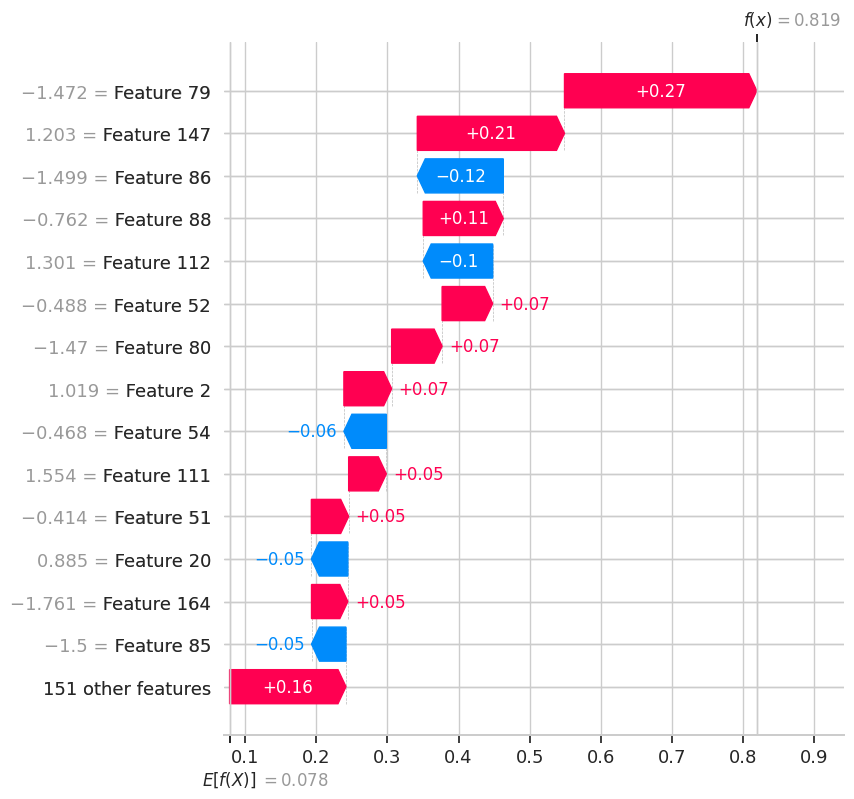

In [27]:
# # Waterfall plot for a single node
# shap.plots.waterfall(shap_values[0], max_display=15)
# plt.tight_layout()
# plt.savefig("./result/shap_waterfall.png", dpi=300)
# plt.close()
# Ensure we have a single-node explanation
sv = shap_values[0]

# Convert base_values to a scalar if it's a 1-element array
if isinstance(sv.base_values, np.ndarray) and sv.base_values.size == 1:
    sv.base_values = sv.base_values.item()

# Plot waterfall
shap.plots.waterfall(sv, max_display=15)
plt.tight_layout()
plt.savefig("./result/shap_waterfall.png", dpi=300)
plt.close()

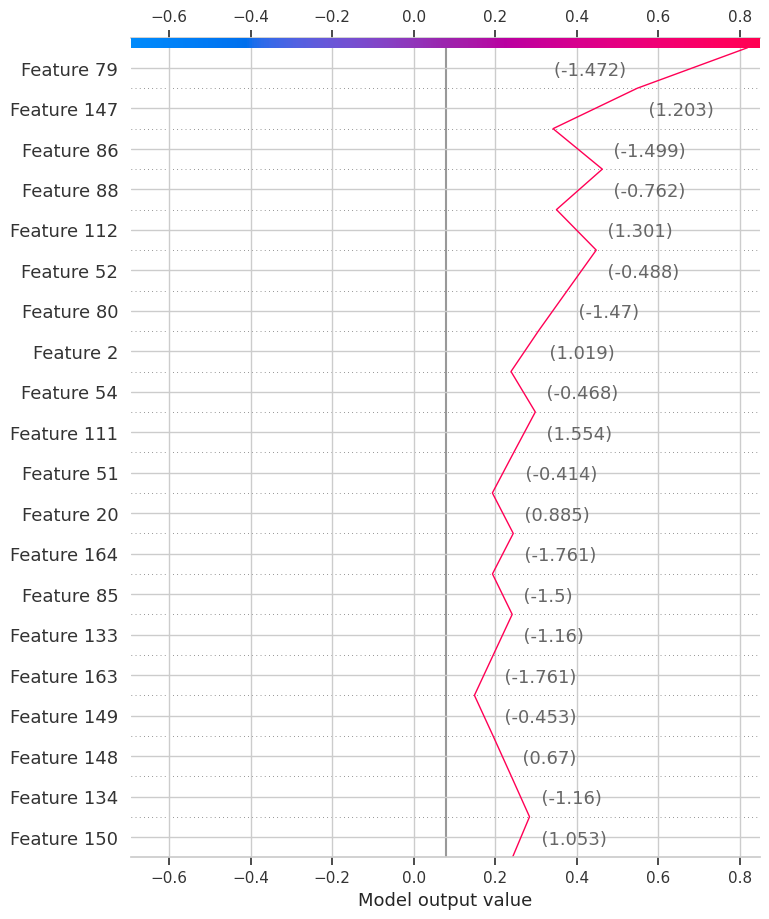

In [28]:
# Plot the Decision Path (Decision Plot)
# Feature names (used for labeling on the plot)
feature_names = [f"Feature {i}" for i in range(data_train.x.shape[1])]

shap.decision_plot(
    base_value=shap_values.base_values[0],
    shap_values=shap_values.values[0],
    features=node_feat[0],
    feature_names=feature_names,
    show=False
)

# Optionally set a title
# plt.title(f"SHAP Decision Plot for Node {node_idx}")

plt.tight_layout()
plt.savefig(f"shap_decision_plot_node{node_idx}.pdf")  # Save as PDF
plt.savefig("./result/shap_decision_plot.png", dpi=300)  # Save as PNG
plt.show()